In [ ]:
!pip install shap -q

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

import shap

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
from google.colab import files

uploaded = files.upload()

Saving heart.csv to heart (1).csv


In [12]:
df = pd.read_csv('heart.csv')

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [13]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

Dataset Shape: (1025, 14)

Column Names:
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [15]:
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [16]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 723


In [17]:
df = df.drop_duplicates()

print("Dataset after removing duplicates:", df.shape)

Dataset after removing duplicates: (302, 14)


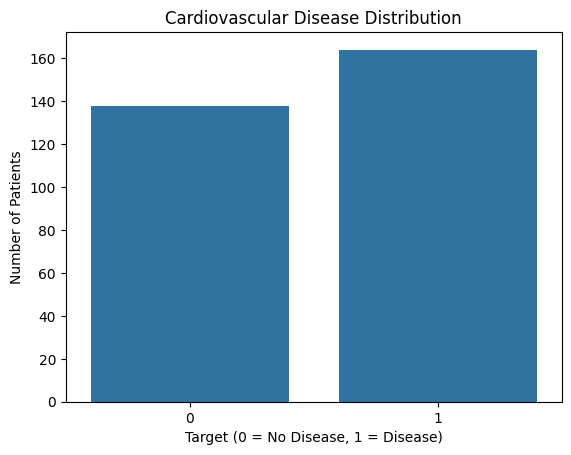

In [18]:
sns.countplot(x='target', data=df)

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

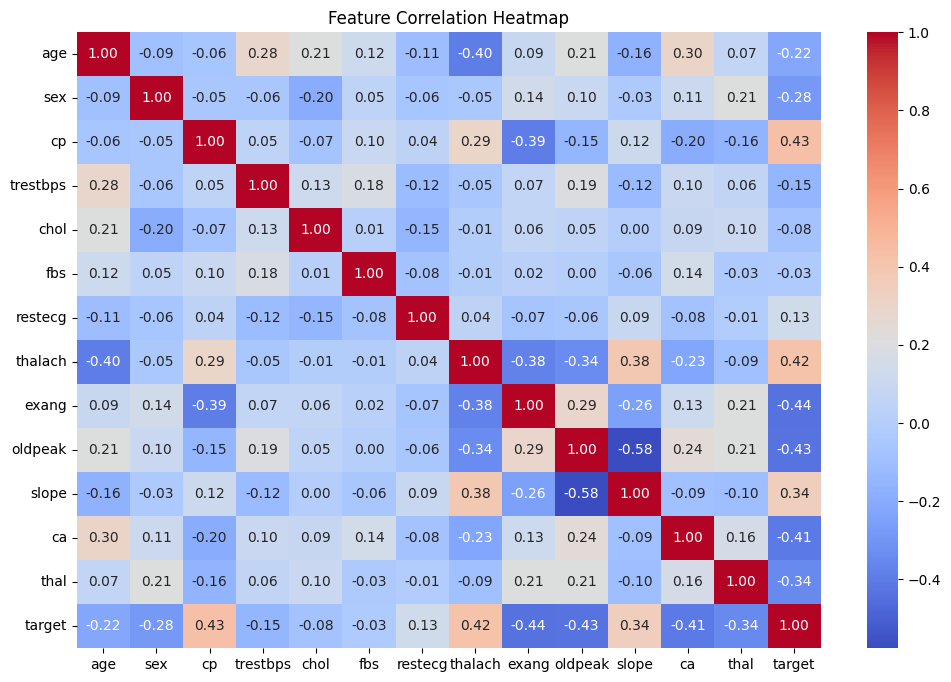

In [20]:
# Calculate correlation
corr = df.corr(numeric_only=True)

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [21]:
X = df.drop('target', axis=1)

y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (302, 13)
Target Shape: (302,)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (241, 13)
Testing Data: (61, 13)


In [23]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions))

Logistic Regression Accuracy: 0.8032786885245902


In [24]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

Random Forest Accuracy: 0.7704918032786885


In [25]:
print("RANDOM FOREST MODEL EVALUATION")

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions))

print("Recall:",
      recall_score(y_test, rf_predictions))

print("F1 Score:",
      f1_score(y_test, rf_predictions))

print("\nClassification Report:")

print(classification_report(y_test, rf_predictions))

RANDOM FOREST MODEL EVALUATION
Accuracy: 0.7704918032786885
Precision: 0.7878787878787878
Recall: 0.7878787878787878
F1 Score: 0.7878787878787878

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



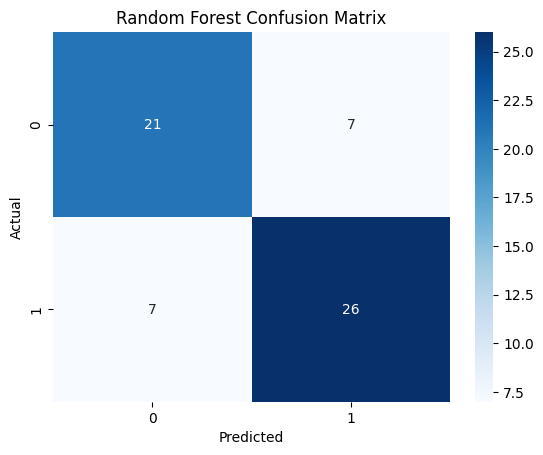

In [26]:
cm = confusion_matrix(y_test, rf_predictions)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [27]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.803279   0.800000  0.848485  0.823529
1        Random Forest  0.770492   0.787879  0.787879  0.787879


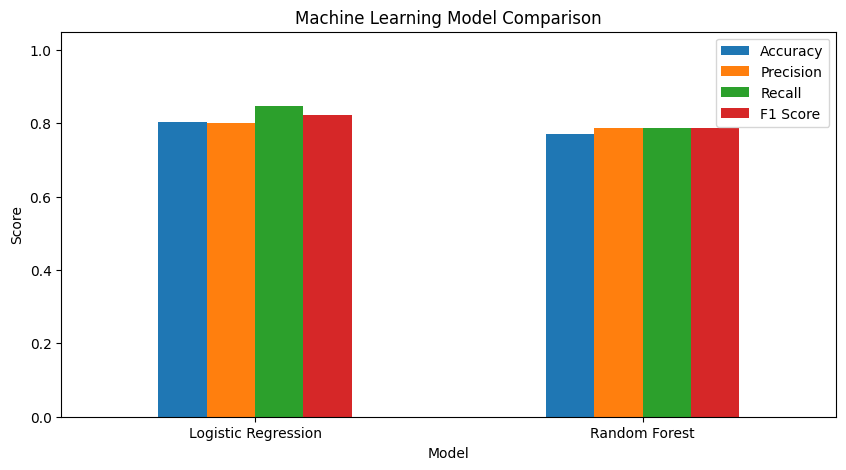

In [28]:
results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Machine Learning Model Comparison")

plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.show()

In [29]:
explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


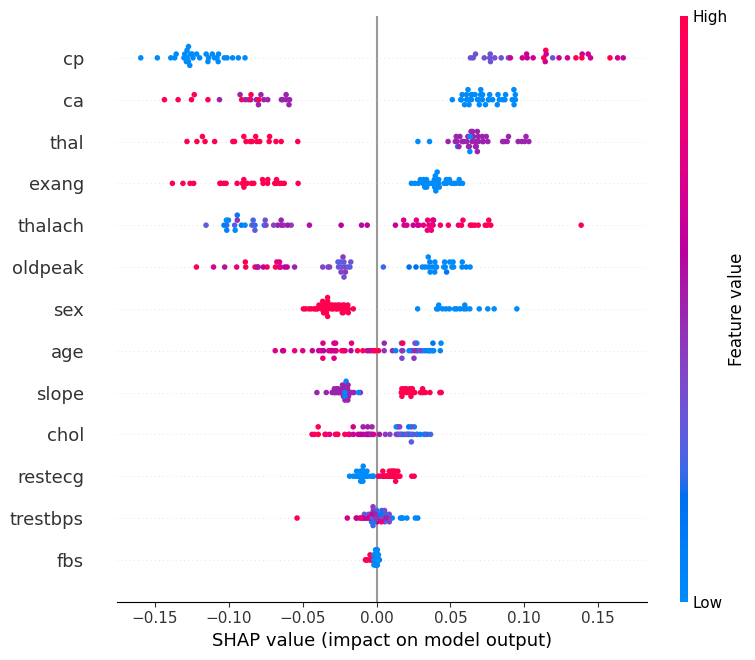

In [30]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test
)

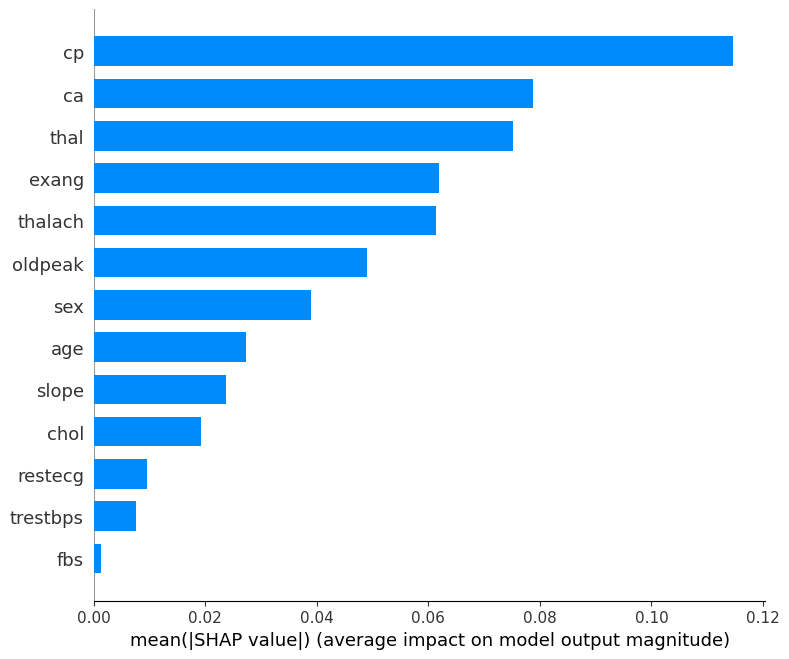

In [31]:
shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    plot_type='bar'
)

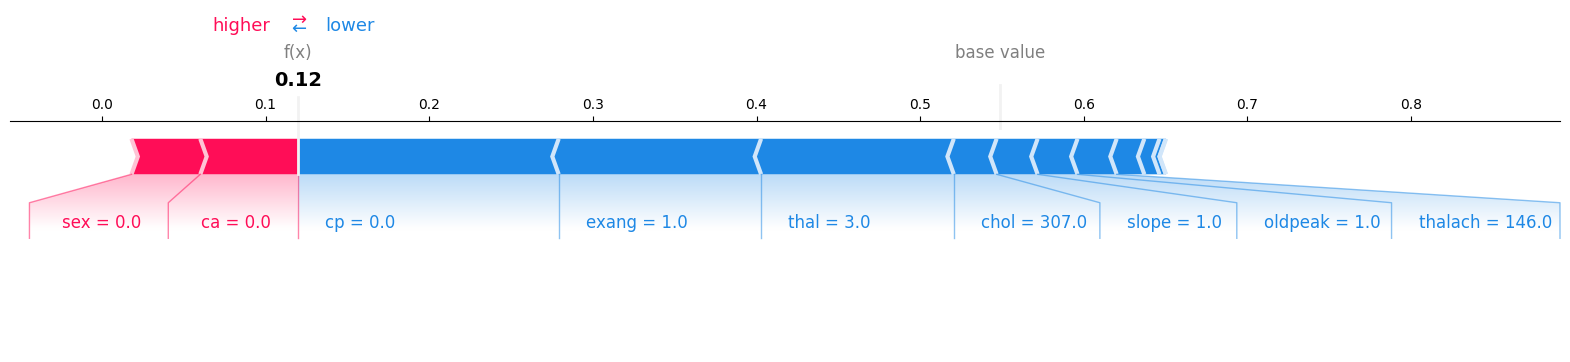

In [ ]:
patient_index = 0

shap.force_plot(
    explainer.expected_value[1],
    shap_values[patient_index, :, 1],
    X_test.iloc[patient_index],
    matplotlib=True
)

In [32]:
new_patient = pd.DataFrame([{
    'age': 55,
    'sex': 1,
    'cp': 0,
    'trestbps': 140,
    'chol': 250,
    'fbs': 0,
    'restecg': 1,
    'thalach': 150,
    'exang': 0,
    'oldpeak': 1.5,
    'slope': 1,
    'ca': 0,
    'thal': 2
}])

prediction = rf_model.predict(new_patient)

probability = rf_model.predict_proba(new_patient)

if prediction[0] == 1:
    print("Model Prediction: Heart Disease Class")
else:
    print("Model Prediction: No Heart Disease Class")

print("Predicted Probability:",
      probability[0][1])

Model Prediction: Heart Disease Class
Predicted Probability: 0.6224379765914906


In [33]:
import joblib

joblib.dump(rf_model, 'cardiovascular_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [34]:
from google.colab import files

files.download('cardiovascular_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from sklearn.metrics import accuracy_score

rf_predictions = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, rf_predictions)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 77.04918032786885 %


In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Precision:",
      precision_score(y_test, rf_predictions))

print("Recall:",
      recall_score(y_test, rf_predictions))

print("F1 Score:",
      f1_score(y_test, rf_predictions))

print("\nDetailed Classification Report:")

print(classification_report(y_test, rf_predictions))

Accuracy: 0.7704918032786885
Precision: 0.7878787878787878
Recall: 0.7878787878787878
F1 Score: 0.7878787878787878

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



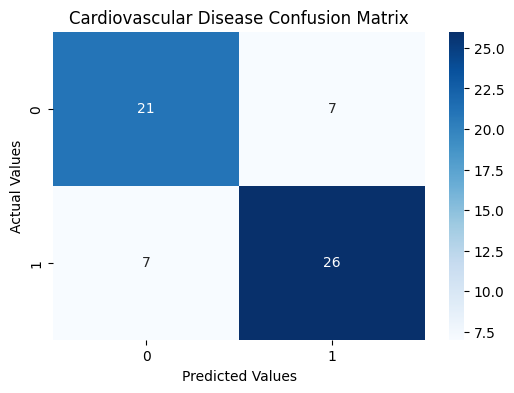

In [37]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Cardiovascular Disease Confusion Matrix")

plt.show()

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

print("Individual Fold Accuracies:", scores)

print("Average Cross Validation Accuracy:",
      scores.mean() * 100, "%")

print("Standard Deviation:",
      scores.std() * 100, "%")

Individual Fold Accuracies: [0.89795918 0.83333333 0.8125     0.9375     0.79166667]
Average Cross Validation Accuracy: 85.45918367346938 %
Standard Deviation: 5.465841935363794 %


In [39]:
import pandas as pd

friend_data = pd.DataFrame([{
    'age': 20,
    'sex': 1,
    'cp': 0,
    'trestbps': 120,
    'chol': 190,
    'fbs': 0,
    'restecg': 1,
    'thalach': 180,
    'exang': 0,
    'oldpeak': 0.0,
    'slope': 2,
    'ca': 0,
    'thal': 2
}])

print(friend_data)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   20    1   0       120   190    0        1      180      0      0.0      2   

   ca  thal  
0   0     2  


In [40]:
prediction = rf_model.predict(friend_data)

probability = rf_model.predict_proba(friend_data)

if prediction[0] == 1:
    print("Prediction: Heart Disease Class")
else:
    print("Prediction: No Heart Disease Class")

print("Model probability for class 1:",
      probability[0][1] * 100, "%")

Prediction: Heart Disease Class
Model probability for class 1: 84.59826635346332 %


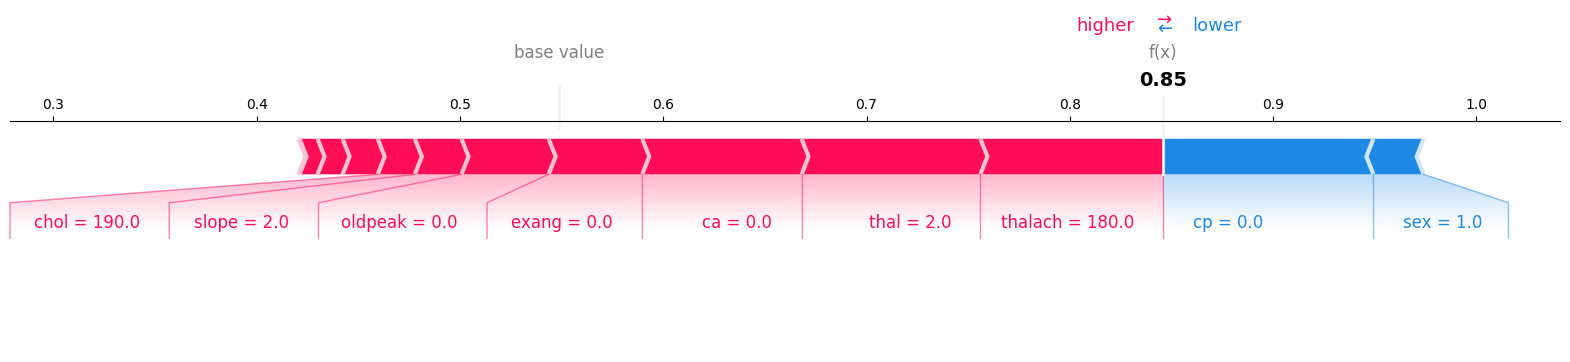

In [41]:
explainer = shap.TreeExplainer(rf_model)

friend_shap_values = explainer.shap_values(friend_data)

shap.force_plot(
    explainer.expected_value[1],
    friend_shap_values[0, :, 1],
    friend_data.iloc[0],
    matplotlib=True
)

In [ ]:
new_patient = pd.DataFrame([{
    'age': 55,
    'sex': 1,
    'cp': 0,
    'trestbps': 130,
    'chol': 240,
    'fbs': 0,
    'restecg': 1,
    'thalach': 150,
    'exang': 0,
    'oldpeak': 1.0,
    'slope': 1,
    'ca': 0,
    'thal': 2
}])

prediction = rf_model.predict(new_patient)

probability = rf_model.predict_proba(new_patient)

print("Predicted Class:", prediction[0])

print("Class 0 Probability:", probability[0][0])

print("Class 1 Probability:", probability[0][1])

Predicted Class: 1
Class 0 Probability: 0.36468904675744584
Class 1 Probability: 0.635310953242554


In [44]:
test_data = pd.DataFrame([
    [45, 1, 0, 120, 220, 0, 1, 170, 0, 0.0, 2, 0, 2],
    [58, 1, 2, 140, 250, 0, 0, 150, 0, 1.0, 1, 1, 2],
    [62, 0, 1, 130, 260, 0, 1, 140, 0, 1.5, 1, 0, 2],
    [50, 1, 3, 150, 280, 1, 0, 130, 1, 2.0, 0, 2, 3],
    [67, 1, 0, 160, 300, 1, 0, 110, 1, 3.0, 0, 2, 3],
    [39, 0, 2, 110, 190, 0, 1, 180, 0, 0.0, 2, 0, 2],
    [55, 1, 1, 135, 235, 0, 1, 155, 0, 0.5, 2, 0, 2],
    [70, 1, 0, 145, 270, 1, 0, 115, 1, 2.5, 0, 3, 3],
    [48, 0, 3, 125, 210, 0, 1, 165, 0, 0.2, 2, 0, 2],
    [60, 1, 2, 138, 245, 0, 0, 135, 1, 1.8, 1, 1, 3]
], columns=[
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal'
])

test_data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,45,1,0,120,220,0,1,170,0,0.0,2,0,2
1,58,1,2,140,250,0,0,150,0,1.0,1,1,2
2,62,0,1,130,260,0,1,140,0,1.5,1,0,2
3,50,1,3,150,280,1,0,130,1,2.0,0,2,3
4,67,1,0,160,300,1,0,110,1,3.0,0,2,3
5,39,0,2,110,190,0,1,180,0,0.0,2,0,2
6,55,1,1,135,235,0,1,155,0,0.5,2,0,2
7,70,1,0,145,270,1,0,115,1,2.5,0,3,3
8,48,0,3,125,210,0,1,165,0,0.2,2,0,2
9,60,1,2,138,245,0,0,135,1,1.8,1,1,3


In [45]:
predictions = rf_model.predict(test_data)

probabilities = rf_model.predict_proba(test_data)

test_data['Predicted_Class'] = predictions

test_data['Class_0_Probability'] = probabilities[:, 0]

test_data['Class_1_Probability'] = probabilities[:, 1]

test_data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Predicted_Class,Class_0_Probability,Class_1_Probability
0,45,1,0,120,220,0,1,170,0,0.0,2,0,2,1,0.136015,0.863985
1,58,1,2,140,250,0,0,150,0,1.0,1,1,2,0,0.506077,0.493923
2,62,0,1,130,260,0,1,140,0,1.5,1,0,2,1,0.208008,0.791992
3,50,1,3,150,280,1,0,130,1,2.0,0,2,3,0,0.747703,0.252297
4,67,1,0,160,300,1,0,110,1,3.0,0,2,3,0,0.984911,0.015089
5,39,0,2,110,190,0,1,180,0,0.0,2,0,2,1,0.035679,0.964321
6,55,1,1,135,235,0,1,155,0,0.5,2,0,2,1,0.115562,0.884438
7,70,1,0,145,270,1,0,115,1,2.5,0,3,3,0,0.964821,0.035179
8,48,0,3,125,210,0,1,165,0,0.2,2,0,2,1,0.030340,0.969660
9,60,1,2,138,245,0,0,135,1,1.8,1,1,3,0,0.750110,0.249890


In [46]:
for i in range(len(test_data)):

    print(f"\nSample {i+1}")

    print("Predicted Class:", predictions[i])

    print("Class 0 Probability:",
          round(probabilities[i][0] * 100, 2), "%")

    print("Class 1 Probability:",
          round(probabilities[i][1] * 100, 2), "%")


Sample 1
Predicted Class: 1
Class 0 Probability: 13.6 %
Class 1 Probability: 86.4 %

Sample 2
Predicted Class: 0
Class 0 Probability: 50.61 %
Class 1 Probability: 49.39 %

Sample 3
Predicted Class: 1
Class 0 Probability: 20.8 %
Class 1 Probability: 79.2 %

Sample 4
Predicted Class: 0
Class 0 Probability: 74.77 %
Class 1 Probability: 25.23 %

Sample 5
Predicted Class: 0
Class 0 Probability: 98.49 %
Class 1 Probability: 1.51 %

Sample 6
Predicted Class: 1
Class 0 Probability: 3.57 %
Class 1 Probability: 96.43 %

Sample 7
Predicted Class: 1
Class 0 Probability: 11.56 %
Class 1 Probability: 88.44 %

Sample 8
Predicted Class: 0
Class 0 Probability: 96.48 %
Class 1 Probability: 3.52 %

Sample 9
Predicted Class: 1
Class 0 Probability: 3.03 %
Class 1 Probability: 96.97 %

Sample 10
Predicted Class: 0
Class 0 Probability: 75.01 %
Class 1 Probability: 24.99 %


In [47]:
test_data.to_csv('heart_test_predictions.csv', index=False)

from google.colab import files
files.download('heart_test_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
import pandas as pd

test_data = pd.DataFrame([
    [25,0,2,110,180,0,0,190,0,0.0,1,0,3],
    [32,1,3,120,210,0,0,185,0,0.0,1,0,3],
    [45,1,2,130,240,0,1,160,0,1.0,2,0,3],
    [52,0,4,140,260,1,1,145,1,2.0,2,1,7],
    [60,1,4,150,280,1,2,120,1,3.0,3,2,7],
    [38,0,1,115,190,0,0,175,0,0.0,1,0,3],
    [55,1,3,135,230,0,1,150,1,1.5,2,1,6],
    [67,1,4,160,290,1,2,110,1,3.5,3,3,7],
    [48,0,2,125,220,0,0,165,0,0.5,1,0,3],
    [72,1,4,170,310,1,2,100,1,4.0,3,2,7]
], columns=[
    'age','sex','cp','trestbps','chol','fbs',
    'restecg','thalach','exang','oldpeak',
    'slope','ca','thal'
])

predictions = rf_model.predict(test_data)

probabilities = rf_model.predict_proba(test_data)

results = test_data.copy()

results['Prediction'] = predictions
results['Confidence'] = probabilities.max(axis=1) * 100

print(results)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   25    0   2       110   180    0        0      190      0      0.0      1   
1   32    1   3       120   210    0        0      185      0      0.0      1   
2   45    1   2       130   240    0        1      160      0      1.0      2   
3   52    0   4       140   260    1        1      145      1      2.0      2   
4   60    1   4       150   280    1        2      120      1      3.0      3   
5   38    0   1       115   190    0        0      175      0      0.0      1   
6   55    1   3       135   230    0        1      150      1      1.5      2   
7   67    1   4       160   290    1        2      110      1      3.5      3   
8   48    0   2       125   220    0        0      165      0      0.5      1   
9   72    1   4       170   310    1        2      100      1      4.0      3   

   ca  thal  Prediction  Confidence  
0   0     3           1   80.611885  
1   0     3           1   83.253

In [49]:
rf_model

RandomForestClassifier(max_depth=5, n_estimators=200, random_state=42)

In [50]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

y_pred = rf_model.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7704918032786885

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61


Confusion Matrix:
[[21  7]
 [ 7 26]]


In [51]:
import pandas as pd

def predict_heart_disease(patient):

    age = patient['age']

    if age < 18:

        print("Using Pediatric Model")

        patient_df = pd.DataFrame([patient])

        prediction = pediatric_model.predict(
            patient_df[pediatric_features]
        )

        if prediction[0] == 1:
            print("Prediction: Heart Disease Detected")
        else:
            print("Prediction: No Heart Disease Detected")

        return prediction[0]

    else:

        print("Using Adult Random Forest Model")

        adult_features = [
            'age', 'sex', 'cp', 'trestbps', 'chol',
            'fbs', 'restecg', 'thalach', 'exang',
            'oldpeak', 'slope', 'ca', 'thal'
        ]

        patient_df = pd.DataFrame([patient])

        prediction = rf_model.predict(
            patient_df[adult_features]
        )

        if prediction[0] == 1:
            print("Prediction: Heart Disease Detected")
        else:
            print("Prediction: No Heart Disease Detected")

        return prediction[0]

print("Prediction function defined successfully!")

Prediction function defined successfully!


In [53]:
import pandas as pd

# Load dataset
df = pd.read_csv('heart.csv')

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset
print("Original dataset: 1025")
print("After removing duplicates:", df.shape[0])

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df['target'].value_counts())

Original dataset: 1025
After removing duplicates: 302

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [54]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Predict
y_pred = rf_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7704918032786885

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61


Confusion Matrix:
[[21  7]
 [ 7 26]]


In [55]:
import joblib

joblib.dump(rf_model, 'heart_disease_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [56]:
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

print("SVM and evaluation libraries imported successfully!")

SVM and evaluation libraries imported successfully!


In [58]:
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        random_state=42
    ))
])

# Train SVM
svm_model.fit(X_train, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test)

print("SVM Model Trained Successfully!")

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

SVM Model Trained Successfully!
SVM Accuracy: 0.7704918032786885


In [59]:
print("SVM MODEL EVALUATION")

print("\nAccuracy:",
      accuracy_score(y_test, svm_predictions))

print("Precision:",
      precision_score(y_test, svm_predictions))

print("Recall:",
      recall_score(y_test, svm_predictions))

print("F1 Score:",
      f1_score(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

SVM MODEL EVALUATION

Accuracy: 0.7704918032786885
Precision: 0.7714285714285715
Recall: 0.8181818181818182
F1 Score: 0.7941176470588235

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.71      0.74        28
           1       0.77      0.82      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



In [60]:
# Predictions from all three models

lr_predictions = lr_model.predict(X_test)

rf_predictions = rf_model.predict(X_test)

svm_predictions = svm_model.predict(X_test)


# Create comparison table

results = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Random Forest',
        'SVM'
    ],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, svm_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions),
        precision_score(y_test, svm_predictions)
    ],

    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions),
        recall_score(y_test, svm_predictions)
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions),
        f1_score(y_test, svm_predictions)
    ]

})

print("MODEL PERFORMANCE COMPARISON")

display(results.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8033,0.8000,0.8485,0.8235
1,Random Forest,0.7705,0.7879,0.7879,0.7879
2,SVM,0.7705,0.7714,0.8182,0.7941


In [61]:
# Prediction probabilities

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

svm_probabilities = svm_model.predict_proba(X_test)[:, 1]


# Calculate ROC-AUC

lr_auc = roc_auc_score(y_test, lr_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)

svm_auc = roc_auc_score(y_test, svm_probabilities)


# Display results

print("ROC-AUC COMPARISON")

print("Logistic Regression:", round(lr_auc, 4))

print("Random Forest:", round(rf_auc, 4))

print("SVM:", round(svm_auc, 4))

ROC-AUC COMPARISON
Logistic Regression: 0.8712
Random Forest: 0.8647
SVM: 0.842


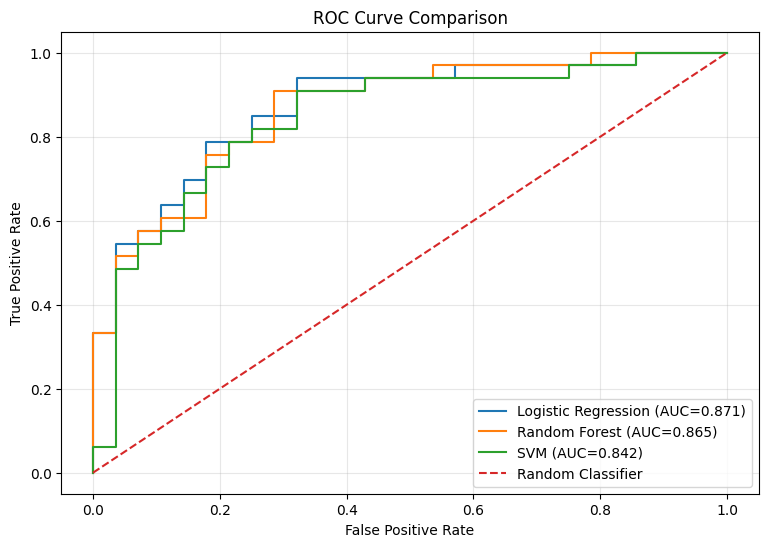

In [62]:
from sklearn.metrics import roc_curve

# Calculate ROC curves

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_probabilities)


# Plot ROC curves

plt.figure(figsize=(9, 6))

plt.plot(lr_fpr, lr_tpr,
         label=f'Logistic Regression (AUC={lr_auc:.3f})')

plt.plot(rf_fpr, rf_tpr,
         label=f'Random Forest (AUC={rf_auc:.3f})')

plt.plot(svm_fpr, svm_tpr,
         label=f'SVM (AUC={svm_auc:.3f})')

plt.plot([0, 1], [0, 1], '--', label='Random Classifier')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [63]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'SVM': svm_model
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    print("\n", name)

    print("Individual Scores:", scores)

    print("Mean Accuracy:", round(scores.mean() * 100, 2), "%")

    print("Standard Deviation:", round(scores.std() * 100, 2), "%")


 Logistic Regression
Individual Scores: [0.89795918 0.79166667 0.83333333 0.95833333 0.70833333]
Mean Accuracy: 83.79 %
Standard Deviation: 8.61 %

 Random Forest
Individual Scores: [0.89795918 0.83333333 0.8125     0.9375     0.79166667]
Mean Accuracy: 85.46 %
Standard Deviation: 5.47 %

 SVM
Individual Scores: [0.89795918 0.83333333 0.875      0.875      0.77083333]
Mean Accuracy: 85.04 %
Standard Deviation: 4.49 %


In [64]:
from sklearn.metrics import roc_auc_score

# Prediction probabilities

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

svm_probabilities = svm_model.predict_proba(X_test)[:, 1]


# Calculate ROC-AUC

lr_auc = roc_auc_score(y_test, lr_probabilities)

rf_auc = roc_auc_score(y_test, rf_probabilities)

svm_auc = roc_auc_score(y_test, svm_probabilities)


# Display results

print("ROC-AUC COMPARISON")

print("Logistic Regression:", round(lr_auc, 4))

print("Random Forest:", round(rf_auc, 4))

print("SVM:", round(svm_auc, 4))

ROC-AUC COMPARISON
Logistic Regression: 0.8712
Random Forest: 0.8647
SVM: 0.842


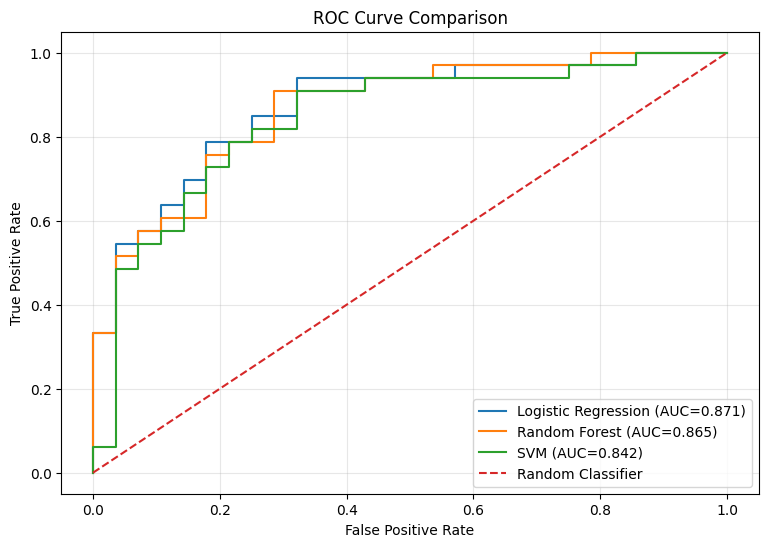

In [65]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_probabilities)


plt.figure(figsize=(9, 6))

plt.plot(lr_fpr, lr_tpr,
         label=f'Logistic Regression (AUC={lr_auc:.3f})')

plt.plot(rf_fpr, rf_tpr,
         label=f'Random Forest (AUC={rf_auc:.3f})')

plt.plot(svm_fpr, svm_tpr,
         label=f'SVM (AUC={svm_auc:.3f})')

plt.plot([0, 1], [0, 1], '--', label='Random Classifier')

plt.xlabel('False Positive Rate')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [66]:
from sklearn.model_selection import cross_validate

models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'SVM': svm_model
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    print("\n", name)

    for metric in scoring:

        values = scores['test_' + metric]

        print(
            metric,
            ":",
            round(values.mean(), 4),
            "+/-",
            round(values.std(), 4)
        )


 Logistic Regression
accuracy : 0.8379 +/- 0.0861
precision : 0.8284 +/- 0.0907
recall : 0.9006 +/- 0.0673
f1 : 0.86 +/- 0.0683
roc_auc : 0.9135 +/- 0.036

 Random Forest
accuracy : 0.8546 +/- 0.0547
precision : 0.8474 +/- 0.0655
recall : 0.9006 +/- 0.0524
f1 : 0.8713 +/- 0.0463
roc_auc : 0.911 +/- 0.0513

 SVM
accuracy : 0.8504 +/- 0.0449
precision : 0.8364 +/- 0.056
recall : 0.908 +/- 0.0396
f1 : 0.8691 +/- 0.035
roc_auc : 0.9132 +/- 0.0391


In [67]:
!pip install lime

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=4ee3b9f118e0edf6a7257e87bcf256750963e6e99280e0718793bed7890b0d02
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [68]:
import lime
import lime.lime_tabular

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [69]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(

    training_data=np.array(X_train),

    feature_names=list(X_train.columns),

    class_names=['No Heart Disease', 'Heart Disease'],

    mode='classification',

    discretize_continuous=True

)

print("LIME Explainer Created Successfully!")

LIME Explainer Created Successfully!


In [70]:
# Select one patient from test data

patient_index = 0

patient_data = X_test.iloc[patient_index].values

# Generate LIME explanation

lime_explanation = explainer_lime.explain_instance(

    data_row=patient_data,

    predict_fn=rf_model.predict_proba,

    num_features=13

)

# Display explanation

lime_explanation.show_in_notebook(show_table=True)

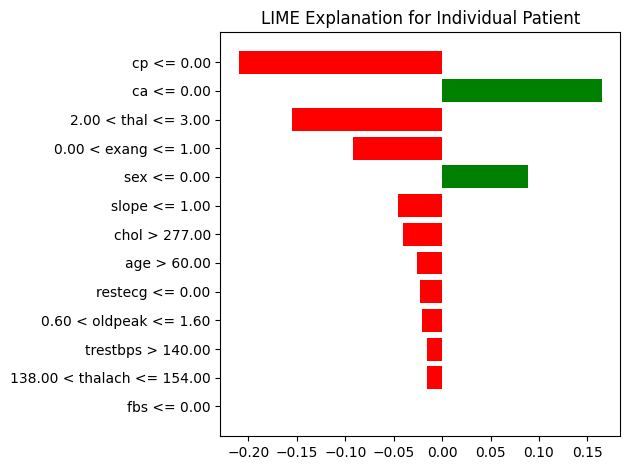

In [71]:
lime_explanation.as_pyplot_figure()

plt.title("LIME Explanation for Individual Patient")

plt.tight_layout()

plt.show()

In [73]:
import joblib

joblib.dump(rf_model, 'final_heart_disease_model.pkl')

print("Final model saved successfully!")
joblib.dump(
    list(X_train.columns),
    'heart_disease_features.pkl'
)

Final model saved successfully!


['heart_disease_features.pkl']

In [75]:
# Unseen synthetic patient records matching your exact 13 features
unseen_patients = pd.DataFrame([
    # Expected 0 (Healthy / Low Risk profiles: younger, normal BP, high max heart rate, no angina)
    {'age': 39, 'sex': 0, 'cp': 2, 'trestbps': 118, 'chol': 195, 'fbs': 0, 'restecg': 1, 'thalach': 178, 'exang': 0, 'oldpeak': 0.0, 'slope': 2, 'ca': 0, 'thal': 2},
    {'age': 44, 'sex': 1, 'cp': 1, 'trestbps': 120, 'chol': 210, 'fbs': 0, 'restecg': 1, 'thalach': 172, 'exang': 0, 'oldpeak': 0.2, 'slope': 2, 'ca': 0, 'thal': 2},
    {'age': 51, 'sex': 0, 'cp': 2, 'trestbps': 124, 'chol': 205, 'fbs': 0, 'restecg': 0, 'thalach': 165, 'exang': 0, 'oldpeak': 0.4, 'slope': 2, 'ca': 0, 'thal': 2},
    {'age': 47, 'sex': 1, 'cp': 3, 'trestbps': 128, 'chol': 220, 'fbs': 0, 'restecg': 1, 'thalach': 168, 'exang': 0, 'oldpeak': 0.0, 'slope': 2, 'ca': 0, 'thal': 2},
    {'age': 53, 'sex': 0, 'cp': 1, 'trestbps': 130, 'chol': 215, 'fbs': 0, 'restecg': 1, 'thalach': 160, 'exang': 0, 'oldpeak': 0.5, 'slope': 1, 'ca': 0, 'thal': 2},

    # Expected 1 (High Risk profiles: older, asymptomatic chest pain cp=0, high oldpeak, blocked vessels ca>0)
    {'age': 63, 'sex': 1, 'cp': 0, 'trestbps': 148, 'chol': 265, 'fbs': 1, 'restecg': 0, 'thalach': 122, 'exang': 1, 'oldpeak': 2.8, 'slope': 0, 'ca': 2, 'thal': 3},
    {'age': 67, 'sex': 1, 'cp': 0, 'trestbps': 155, 'chol': 280, 'fbs': 0, 'restecg': 0, 'thalach': 115, 'exang': 1, 'oldpeak': 3.2, 'slope': 0, 'ca': 3, 'thal': 3},
    {'age': 59, 'sex': 1, 'cp': 0, 'trestbps': 142, 'chol': 250, 'fbs': 1, 'restecg': 0, 'thalach': 130, 'exang': 1, 'oldpeak': 2.1, 'slope': 1, 'ca': 2, 'thal': 3},
    {'age': 61, 'sex': 0, 'cp': 0, 'trestbps': 150, 'chol': 295, 'fbs': 0, 'restecg': 0, 'thalach': 126, 'exang': 1, 'oldpeak': 2.5, 'slope': 1, 'ca': 2, 'thal': 3},
    {'age': 56, 'sex': 1, 'cp': 0, 'trestbps': 138, 'chol': 248, 'fbs': 0, 'restecg': 0, 'thalach': 134, 'exang': 1, 'oldpeak': 1.9, 'slope': 1, 'ca': 1, 'thal': 3}
])

# Eita change koro: 1 = Healthy, 0 = Heart Disease
true_labels = [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]

# Disease (class 0) hoar probability dekhate [:, 0] use koro:
comparison_df = pd.DataFrame({
    'Actual_Target': true_labels,
    'LR_Predicted': lr_new_preds,
    'RF_Predicted': rf_new_preds,
    'LR_Disease_Prob (%)': np.round(lr_model.predict_proba(unseen_patients)[:, 0] * 100, 1),
    'RF_Disease_Prob (%)': np.round(rf_model.predict_proba(unseen_patients)[:, 0] * 100, 1)
})

print(comparison_df)
print(f"\nFinal Unseen Data Accuracy (Logistic Regression): {accuracy_score(true_labels, lr_new_preds)*100:.2f}%")
print(f"Final Unseen Data Accuracy (Random Forest):       {accuracy_score(true_labels, rf_new_preds)*100:.2f}%")

   Actual_Target  LR_Predicted  RF_Predicted  LR_Disease_Prob (%)  \
0              1             1             1                  0.3   
1              1             1             1                  7.2   
2              1             1             1                  0.9   
3              1             1             1                  1.5   
4              1             1             1                  3.8   
5              0             0             0                 99.9   
6              0             0             0                100.0   
7              0             0             0                 99.7   
8              0             0             0                 98.5   
9              0             0             0                 98.8   

   RF_Disease_Prob (%)  
0                  1.7  
1                  4.3  
2                  3.1  
3                  9.2  
4                  4.1  
5                 99.6  
6                 98.5  
7                 99.7  
8              

DATASET INFORMATION
-------------------
Total unique records: 302
Total features: 13
Missing values: 0

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Training records: 241
Testing records: 61

LOGISTIC REGRESSION

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61

Confusion Matrix:
[[21  7]
 [ 5 28]]

RANDOM FOREST

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61

Confus

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8033,0.8000,0.8485,0.8235,0.8712
Random Forest,0.7705,0.7879,0.7879,0.7879,0.8647
SVM,0.7705,0.7714,0.8182,0.7941,0.8420




5-FOLD CROSS VALIDATION
ACCURACY: 83.79% +/- 8.61%
PRECISION: 82.84% +/- 9.07%
RECALL: 90.06% +/- 6.73%
F1: 86.00% +/- 6.83%
ROC_AUC: 91.35% +/- 3.60%
ACCURACY: 85.46% +/- 5.47%
PRECISION: 84.74% +/- 6.55%
RECALL: 90.06% +/- 5.24%
F1: 87.13% +/- 4.63%
ROC_AUC: 91.10% +/- 5.13%
ACCURACY: 85.04% +/- 4.49%
PRECISION: 83.64% +/- 5.60%
RECALL: 90.80% +/- 3.96%
F1: 86.91% +/- 3.50%
ROC_AUC: 91.32% +/- 3.91%

CROSS VALIDATION SUMMARY


,ACCURACY,PRECISION,RECALL,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.8379,0.8284,0.9006,0.8600,0.9135
Random Forest,0.8546,0.8474,0.9006,0.8713,0.9110
SVM,0.8504,0.8364,0.9080,0.8691,0.9132



Majority Class Baseline Accuracy: 54.1 %


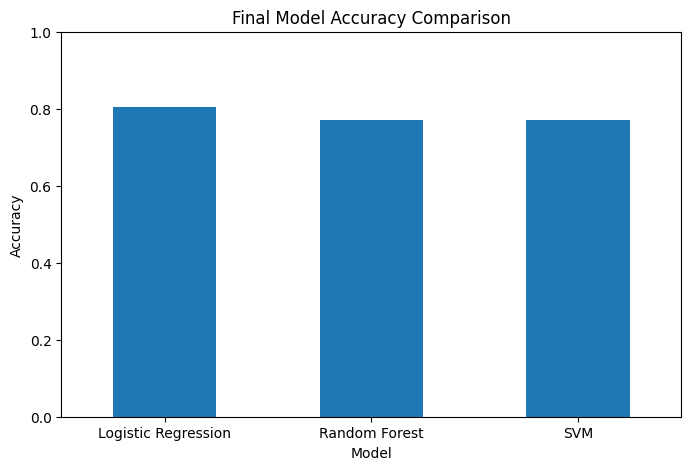

<Figure size 800x600 with 0 Axes>

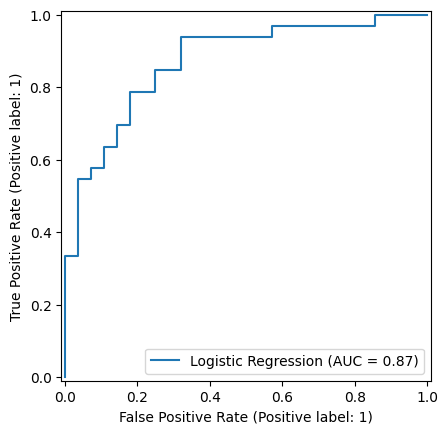

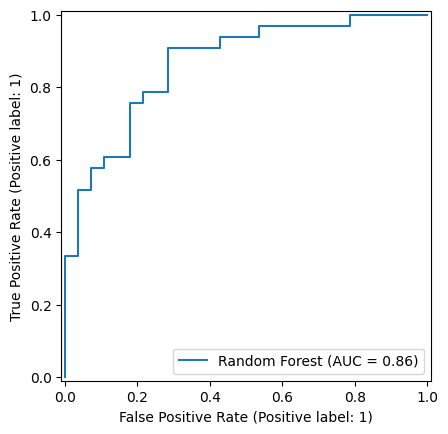

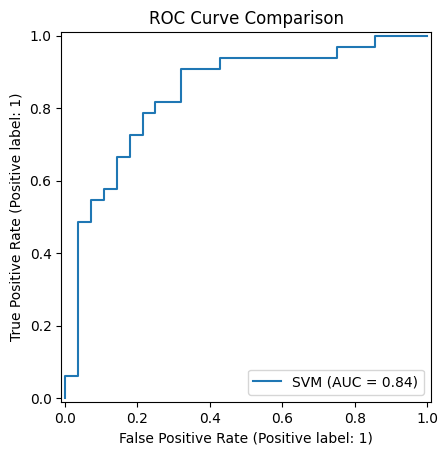


FINAL MODEL
Selected Model: Random Forest
CV Accuracy: 85.46 %
Test Accuracy: 77.05 %

Model and feature list saved successfully!


In [76]:
# ============================================
# FINAL MODEL PERFORMANCE AND ACCURACY CHECK
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Prepare dataset
final_df = df.copy()
final_df = final_df.drop_duplicates()

X = final_df.drop(columns=['target'])
y = final_df['target']

print("DATASET INFORMATION")
print("-------------------")
print("Total unique records:", len(final_df))
print("Total features:", X.shape[1])
print("Missing values:", X.isnull().sum().sum())
print("\nTarget distribution:")
print(y.value_counts())

# 2. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 3. Define models
models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42
    ),

    "SVM": Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(
            kernel='rbf',
            C=1.0,
            gamma='scale',
            probability=True,
            random_state=42
        ))
    ])
}

# 4. Train and evaluate models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    print("\n================================")
    print(name.upper())
    print("================================")

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


# 5. Model comparison
results_df = pd.DataFrame(results).set_index("Model")

print("\n\nFINAL MODEL COMPARISON")
print("======================")
display(results_df.round(4))

# 6. Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc'
}

cv_results = []

print("\n\n5-FOLD CROSS VALIDATION")
print("=======================")

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    row = {"Model": name}

    for metric in scoring:
        mean_score = scores['test_' + metric].mean()
        std_score = scores['test_' + metric].std()

        row[metric.upper()] = mean_score
        print(
            f"{metric.upper()}: "
            f"{mean_score * 100:.2f}% "
            f"+/- {std_score * 100:.2f}%"
        )

    cv_results.append(row)

cv_df = pd.DataFrame(cv_results).set_index("Model")

print("\nCROSS VALIDATION SUMMARY")
display(cv_df.round(4))

# 7. Majority-class baseline
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

baseline_accuracy = accuracy_score(
    y_test,
    baseline.predict(X_test)
)

print("\nMajority Class Baseline Accuracy:",
      round(baseline_accuracy * 100, 2), "%")

# 8. Plot model accuracy
results_df['Accuracy'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Final Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# 9. ROC Curve
plt.figure(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name
    )

plt.title("ROC Curve Comparison")
plt.show()

# 10. Save final selected model
# Selection based on highest mean 5-fold CV accuracy

best_model_name = cv_df['ACCURACY'].idxmax()
best_model = models[best_model_name]

joblib.dump(best_model, 'final_heart_disease_model.pkl')
joblib.dump(list(X.columns), 'heart_disease_features.pkl')

print("\n================================")
print("FINAL MODEL")
print("================================")
print("Selected Model:", best_model_name)
print("CV Accuracy:",
      round(cv_df.loc[best_model_name, 'ACCURACY'] * 100, 2), "%")
print("Test Accuracy:",
      round(results_df.loc[best_model_name, 'Accuracy'] * 100, 2), "%")

print("\nModel and feature list saved successfully!")